# Notebook 16 — True Multi-Stage Cascade Optimization (MVP First)

**Pipeline:** Notebook08 Top-500 → real LightGBM pre-ranking Top-M → DeepFM on only M candidates → frozen MMR λ=0.9 → Top-20.

**Selection:** Validation ONLY. Test is not read until M is frozen. Notebook13 full-500 DeepFM+MMR is the reference, **not** an exact-parity target after pruning. Validation evaluation uses frozen Notebook10/11 scores as an exact *score replay*, not live inference; the service uses actual model inference. The benchmark is local HTTP with precomputed candidates/features; it is not live retrieval or a production SLO.

Place `notebook16_service.py` beside `notebook15_service.py` at project root. Dependencies: same as Notebook15 plus `duckdb`, `matplotlib`, `httpx`, `uvicorn`.

In [1]:
from pathlib import Path
import os,sys,json,time,random,subprocess,socket,contextlib,platform
import numpy as np,pandas as pd,duckdb,matplotlib.pyplot as plt,httpx
from IPython.display import display
SEED=42;KEEP_CHOICES=(100,150,200,300);KS=(20,50,100);LAM=.9
N_REQUESTS=60;WARMUP=5;PORT=8016
# Guardrails relative to full-500 Notebook13 MMR baseline on validation
MAX_NDCG20_REL_DROP=.05;MAX_RECALL20_ABS_DROP=.005
ROOT=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'data'/'processed'/'notebook02.duckdb').exists()),None)
assert ROOT is not None,'Open notebook from project root or notebooks/'
OUT=ROOT/'data'/'processed';REP=ROOT/'data'/'reports';PLOTS=REP/'notebook16_plots'
REP.mkdir(exist_ok=True,parents=True);PLOTS.mkdir(exist_ok=True,parents=True)
assert (ROOT/'notebook16_service.py').exists() and (ROOT/'notebook15_service.py').exists(),'Copy both service files into project root'
print('ROOT',ROOT)

ROOT C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks


## 1. Validation-only candidate cascade sweep

Align by `(user_id,item_id)`; use LightGBM scores to prune, then DeepFM scores to re-rank. Do **not** use validation labels to rank candidates. Frozen MMR behavior is identical to Notebook13 within the retained pool.

In [2]:
CATS=['category_id','parent_category_id','root_category_id']
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from notebook16_service import mmr_general

def load_score_replay(split):
    f=pd.read_parquet(OUT/f'{split}_ranking_features_top500.parquet',columns=['user_id','item_id']+CATS)
    l=pd.read_parquet(OUT/f'{split}_lightgbm_binary_top500.parquet')
    d=pd.read_parquet(OUT/f'{split}_deepfm_deepfm_top500.parquet')
    r=pd.read_parquet(OUT/f'{split}_fusion_rrf_top500.parquet',columns=['user_id','item_id','retrieval_rank'])
    for name,df in [('features',f),('lgbm',l),('deepfm',d),('retrieval',r)]:
        assert not df[['user_id','item_id']].duplicated().any(),(split,name,'duplicate keys')
    # Keep only required columns, avoid name collisions.
    l=l[['user_id','item_id','score']].rename(columns={'score':'lgbm_score'})
    d=d[['user_id','item_id','score','label','model_rank']].rename(columns={'score':'deepfm_score'})
    x=r.merge(f,on=['user_id','item_id'],validate='one_to_one',how='left',indicator=True)
    assert x['_merge'].eq('both').all();x=x.drop(columns='_merge')
    x=x.merge(l,on=['user_id','item_id'],validate='one_to_one').merge(d,on=['user_id','item_id'],validate='one_to_one')
    x=x.sort_values(['user_id','retrieval_rank','item_id'],kind='stable').reset_index(drop=True)
    counts=x.groupby('user_id',sort=False).size();assert counts.min()==counts.max()==500
    assert x[['lgbm_score','deepfm_score','label']].notna().all().all()
    return x

con=duckdb.connect(str(OUT/'notebook02.duckdb'),read_only=True)
def eligible(split):
    p=con.execute(f'SELECT user_id,COUNT(*) AS n FROM {split}_positives GROUP BY user_id').df()
    return dict(zip(p.user_id.astype('int64'),p.n.astype('int64')))

VAL=load_score_replay('validation');POS_VAL=eligible('validation')
assert set(VAL.user_id.unique())==set(POS_VAL)
print('Validation users',len(POS_VAL),'rows',len(VAL))

Validation users 3657 rows 1828500


In [3]:
def cascade_rank(df,keep):
    # Returns per-user ordered item IDs. Scores are frozen precomputed model outputs.
    result={}
    for uid,g in df.groupby('user_id',sort=False):
        ids=g.item_id.to_numpy(dtype=np.int64);rr=g.retrieval_rank.to_numpy()
        lg=g.lgbm_score.to_numpy(dtype=np.float64);ds=g.deepfm_score.to_numpy(dtype=np.float64)
        pre=np.lexsort((ids,rr,-lg))[:keep]
        fine=pre[np.lexsort((ids[pre],rr[pre],-ds[pre]))]
        cat=g.iloc[fine][CATS].apply(pd.to_numeric,errors='coerce').fillna(-1).to_numpy(dtype=np.int64)
        local=mmr_general(ds[fine],cat,LAM,pool=min(150,keep),depth=min(100,keep))
        result[int(uid)]=ids[fine[local]]
    return result

def baseline_rank(split):
    ref=pd.read_parquet(OUT/f'{split}_mmr_top500.parquet',columns=['user_id','item_id','mmr_rank'])
    return {int(u):g.sort_values('mmr_rank').item_id.to_numpy(dtype=np.int64) for u,g in ref.groupby('user_id',sort=False)}

def evaluate_rank(df,ranks,positives,split,method,keep):
    indexed={int(u):g.set_index('item_id') for u,g in df.groupby('user_id',sort=False)}
    n=len(ranks); assert n==len(indexed)==len(positives)
    total=sum(positives.values()); rows=[]
    for k in KS:
        hits=0;uh=0;ndcgs=[];cover=[];ilds=[];missing=[];overlap=[]
        for uid,order in ranks.items():
            g=indexed[uid];top=order[:k];assert len(top)==k and len(set(top))==k
            y=g.loc[top,'label'].to_numpy(dtype=np.int8)
            h=int(y.sum());hits+=h;uh+=int(h>0)
            discount=1/np.log2(np.arange(2,k+2));ideal=discount[:min(positives[uid],k)].sum()
            ndcgs.append(float((y*discount).sum()/ideal))
            cat=g.loc[top,CATS].apply(pd.to_numeric,errors='coerce').fillna(-1).to_numpy(dtype=np.int64)
            leaf=cat[:,0];cover.append(int(np.unique(leaf[leaf>=0]).size));missing.append(float(np.mean(leaf<0)))
            # Pairwise hierarchical similarity: leaf 1.0 > parent .7 > root .4; missing never matches.
            sim=np.zeros((k,k),dtype=np.float32)
            for col,value in ((2,.4),(1,.7),(0,1.)):
                v=cat[:,col];sim=np.where((v[:,None]==v[None,:])&(v[:,None]>=0),np.float32(value),sim)
            tri=np.triu_indices(k,1);ilds.append(float(np.mean(1-sim[tri])))
        rows.append({'split':split,'method':method,'keep':keep,'k':k,'hits':hits,'eligible_positive_pairs':total,
                     'recall_micro':hits/total,'hit_rate':uh/n,'ndcg':float(np.mean(ndcgs)),
                     'category_coverage':float(np.mean(cover)),'intra_list_diversity':float(np.mean(ilds)),
                     'missing_category_rate':float(np.mean(missing)),'user_coverage':1.0})
    return rows

BASE_VAL=baseline_rank('validation')
base_rows=evaluate_rank(VAL,BASE_VAL,POS_VAL,'validation','full500_reference',500)
VAL_RANKS={};rows=list(base_rows)
for keep in KEEP_CHOICES:
    t=time.perf_counter();VAL_RANKS[keep]=cascade_rank(VAL,keep)
    rows+=evaluate_rank(VAL,VAL_RANKS[keep],POS_VAL,'validation',f'cascade_{keep}',keep)
    print('Validation keep',keep,'seconds',round(time.perf_counter()-t,1))
VAL_METRICS=pd.DataFrame(rows);VAL_METRICS.to_csv(REP/'notebook16_validation_cascade_sweep.csv',index=False)
display(VAL_METRICS[VAL_METRICS.k==20])

Validation keep 100 seconds 20.6
Validation keep 150 seconds 63.1
Validation keep 200 seconds 22.6
Validation keep 300 seconds 64.6


,split,method,keep,k,hits,eligible_positive_pairs,recall_micro,hit_rate,ndcg,category_coverage,intra_list_diversity,missing_category_rate,user_coverage
0,validation,full500_reference,500,20,696,9020,0.077162,0.145201,0.053906,4.348646,0.308291,0.054102,1.0
3,validation,cascade_100,100,20,691,9020,0.076608,0.144928,0.053778,4.015040,0.296440,0.059926,1.0
6,validation,cascade_150,150,20,694,9020,0.076940,0.144928,0.053878,4.259229,0.310576,0.061553,1.0
9,validation,cascade_200,200,20,698,9020,0.077384,0.145748,0.054097,4.149850,0.299288,0.056330,1.0
12,validation,cascade_300,300,20,700,9020,0.077605,0.145748,0.054033,4.218759,0.300470,0.054772,1.0


## 2. Freeze pruning size using Validation ONLY

Guardrails: NDCG@20 relative drop ≤5%, Recall@20 absolute drop ≤0.005. Among eligible choices choose **smallest keep** to prioritize compute reduction. If none pass, fallback to 500 (no pruning). These thresholds are explicit MVP engineering choices, not tuned on Test.

In [4]:
b=VAL_METRICS[(VAL_METRICS.method=='full500_reference')&(VAL_METRICS.k==20)].iloc[0]
v=VAL_METRICS[(VAL_METRICS.method!='full500_reference')&(VAL_METRICS.k==20)].copy()
v['ndcg_relative_drop']=1-v.ndcg/b.ndcg
v['recall_absolute_drop']=b.recall_micro-v.recall_micro
v['eligible']=(v.ndcg_relative_drop<=MAX_NDCG20_REL_DROP)&(v.recall_absolute_drop<=MAX_RECALL20_ABS_DROP)
SELECTED_KEEP=int(v[v.eligible].keep.min()) if v.eligible.any() else 500
CONFIG={'selected_on':'validation','selected_keep':SELECTED_KEEP,'mmr_lambda':LAM,
        'guardrails':{'max_ndcg20_relative_drop':MAX_NDCG20_REL_DROP,'max_recall20_absolute_drop':MAX_RECALL20_ABS_DROP},
        'tested_keeps':list(KEEP_CHOICES),'selection_policy':'smallest eligible keep; fallback 500',
        'test_used_for_selection':False,'seed':SEED}
(REP/'notebook16_cascade_config.json').write_text(json.dumps(CONFIG,indent=2),encoding='utf-8')
print('FROZEN selected keep:',SELECTED_KEEP);display(v[['keep','ndcg','recall_micro','ndcg_relative_drop','recall_absolute_drop','eligible']])

FROZEN selected keep: 100


,keep,ndcg,recall_micro,ndcg_relative_drop,recall_absolute_drop,eligible
3,100,0.053778,0.076608,0.002382,0.000554,True
6,150,0.053878,0.076940,0.000530,0.000222,True
9,200,0.054097,0.077384,-0.003535,-0.000222,True
12,300,0.054033,0.077605,-0.002347,-0.000443,True


## 3. One-time Test evaluation after selection

Only now load Test. Report relevance, diversity, overlap with Notebook13 full-500 reference. The cascade cannot preserve exact parity with the full pipeline after pruning.

In [5]:
TEST=load_score_replay('test');POS_TEST=eligible('test');BASE_TEST=baseline_rank('test')
TEST_RANKS=cascade_rank(TEST,SELECTED_KEEP) if SELECTED_KEEP!=500 else cascade_rank(TEST,500)
TEST_METRICS=pd.DataFrame(evaluate_rank(TEST,BASE_TEST,POS_TEST,'test','full500_reference',500)+
                          evaluate_rank(TEST,TEST_RANKS,POS_TEST,'test','cascade_selected',SELECTED_KEEP))
TEST_METRICS.to_csv(REP/'notebook16_test_cascade_metrics.csv',index=False)
overlap=[]
for uid,order in TEST_RANKS.items():
    ref=BASE_TEST[uid]
    overlap.append({'user_id':uid,'top20_overlap_count':len(set(order[:20])&set(ref[:20])),
                    'top20_exact':bool(np.array_equal(order[:20],ref[:20])),
                    'top20_jaccard':len(set(order[:20])&set(ref[:20]))/len(set(order[:20])|set(ref[:20]))})
OVERLAP=pd.DataFrame(overlap);OVERLAP.to_csv(REP/'notebook16_test_top20_overlap.csv',index=False)
print('Test Top20 mean overlap:',OVERLAP.top20_overlap_count.mean()/20,'exact rate:',OVERLAP.top20_exact.mean())
display(TEST_METRICS)

Test Top20 mean overlap: 0.9183510638297872 exact rate: 0.20128779395296753


,split,method,keep,k,hits,eligible_positive_pairs,recall_micro,hit_rate,ndcg,category_coverage,intra_list_diversity,missing_category_rate,user_coverage
0,test,full500_reference,500,20,609,8214,0.074142,0.132979,0.055652,4.781355,0.311540,0.048754,1.0
1,test,full500_reference,500,50,895,8214,0.108960,0.181971,0.064919,11.915174,0.368384,0.039535,1.0
2,test,full500_reference,500,100,1184,8214,0.144144,0.227884,0.072412,23.640258,0.429640,0.046296,1.0
3,test,cascade_selected,100,20,622,8214,0.075724,0.135498,0.056089,4.320269,0.296372,0.055361,1.0
4,test,cascade_selected,100,50,904,8214,0.110056,0.183371,0.065299,8.099384,0.312504,0.059345,1.0
5,test,cascade_selected,100,100,1170,8214,0.142440,0.226764,0.072581,15.271277,0.370462,0.043331,1.0


## 4. Launch FastAPI and verify real-model parity against score replay

The service scores all 500 with LightGBM, but **only the retained M** with DeepFM. Its output must match the cached-score cascade for the same users. If parity fails, STOP: do not interpret HTTP latency.

In [6]:
env=os.environ.copy();env['NOTEBOOK15_PROJECT_ROOT']=str(ROOT);env['NOTEBOOK15_SPLIT']='test'
server=None
cmd=[sys.executable,'-m','uvicorn','notebook16_service:app','--host','127.0.0.1','--port',str(PORT),'--workers','1']
server=subprocess.Popen(cmd,cwd=str(ROOT),env=env,stdout=(REP/'notebook16_uvicorn.log').open('w',encoding='utf-8'),stderr=subprocess.STDOUT)
client=httpx.Client(base_url=f'http://127.0.0.1:{PORT}',timeout=120)
ready=False
for _ in range(90):
    if server.poll() is not None:break
    try:
        h=client.get('/health');
        if h.status_code==200:ready=True;break
    except (httpx.ConnectError,httpx.ReadTimeout):pass
    time.sleep(1)
assert ready,'Server failed startup; inspect data/reports/notebook16_uvicorn.log'
print('Health:',h.json())

Health: {'status': 'ok', 'device': 'cuda', 'users_cached': 3572, 'prerank_keep': 100, 'mmr_lambda': 0.9, 'real_model_inference': True, 'retrieval': 'precomputed', 'features': 'precomputed'}


In [7]:
rng=np.random.default_rng(SEED)
USERS=np.array(sorted(TEST_RANKS),dtype=np.int64)
SAMPLED=rng.choice(USERS,size=min(N_REQUESTS,len(USERS)),replace=False)
assert len(SAMPLED)>WARMUP
PARITY=[]
for uid in SAMPLED:
    response=client.get('/recommend',params={'user_id':int(uid),'k':20});response.raise_for_status()
    data=response.json();expected=TEST_RANKS[int(uid)][:20].tolist()
    PARITY.append({'user_id':int(uid),'exact_match':data['items']==expected,'returned':len(data['items']),
                   'fine_rank_count':data['fine_rank_count'],'expected_keep':SELECTED_KEEP})
PARITY=pd.DataFrame(PARITY);PARITY.to_csv(REP/'notebook16_serving_parity_audit.csv',index=False)
assert PARITY.exact_match.all(),f'Service/cached-score parity failed for {len(PARITY)-PARITY.exact_match.sum()} users'
assert PARITY.fine_rank_count.eq(SELECTED_KEEP).all()
print('Service vs score-replay Top20 exact parity:',PARITY.exact_match.mean())

Service vs score-replay Top20 exact parity: 1.0


## 5. Local sequential HTTP benchmark

Warm model, one worker, localhost, no concurrent load. P50/P95/P99 computed from **HTTP round-trip**, with server-side timings reported separately. Baseline Notebook15 numbers are historical and not an A/B benchmark on identical conditions.

In [8]:
for uid in SAMPLED[:WARMUP]:client.get('/recommend',params={'user_id':int(uid),'k':20}).raise_for_status()
SAMPLES=[];STAGES=[]
for uid in SAMPLED[WARMUP:]:
    start=time.perf_counter();r=client.get('/recommend',params={'user_id':int(uid),'k':20});elapsed=(time.perf_counter()-start)*1000
    r.raise_for_status();data=r.json()
    SAMPLES.append({'user_id':int(uid),'http_ms':elapsed,'server_ms':data['total_ms'],
                    'candidate_count':data['candidate_count'],'fine_rank_count':data['fine_rank_count']})
    for stage,ms in data['stage_ms'].items():STAGES.append({'user_id':int(uid),'stage':stage,'latency_ms':ms})
SAMPLES=pd.DataFrame(SAMPLES);STAGES=pd.DataFrame(STAGES)
SAMPLES.to_csv(REP/'notebook16_http_request_samples.csv',index=False)
STAGES.to_csv(REP/'notebook16_stage_samples.csv',index=False)
def latency(v):
    v=np.asarray(v,dtype=float)
    return {'n':len(v),'mean_ms':float(v.mean()),'p50_ms':float(np.percentile(v,50)),
            'p95_ms':float(np.percentile(v,95)),'p99_ms':float(np.percentile(v,99)),
            'sequential_qps':float(1000/v.mean())}
HTTP=latency(SAMPLES.http_ms);SERVER=latency(SAMPLES.server_ms)
STAGE_METRICS=STAGES.groupby('stage').latency_ms.agg(['mean','median','max']).reset_index()
STAGE_METRICS.to_csv(REP/'notebook16_stage_latency.csv',index=False)
print('HTTP',HTTP,'Server',SERVER);display(STAGE_METRICS)

HTTP {'n': 55, 'mean_ms': 21.553885454671796, 'p50_ms': 21.231499998975778, 'p95_ms': 24.493280001843228, 'p99_ms': 26.20357400024659, 'sequential_qps': 46.395347238112485} Server {'n': 55, 'mean_ms': 18.64163090909091, 'p50_ms': 18.5329, 'p95_ms': 21.16377, 'p99_ms': 22.527688, 'sequential_qps': 53.64337513582746}


,stage,mean,median,max
0,candidate_pruning,1.337318,1.2790,2.2047
1,deepfm_inference,2.368389,2.1961,4.3591
2,deepfm_preprocess,4.445002,4.4014,5.5033
3,lgbm_inference,2.788989,2.7614,3.7555
4,lgbm_preprocess,4.097562,4.1886,5.2119
5,mmr_greedy,3.578327,3.5359,5.1624


## 6. Visualize and export reproducible reports

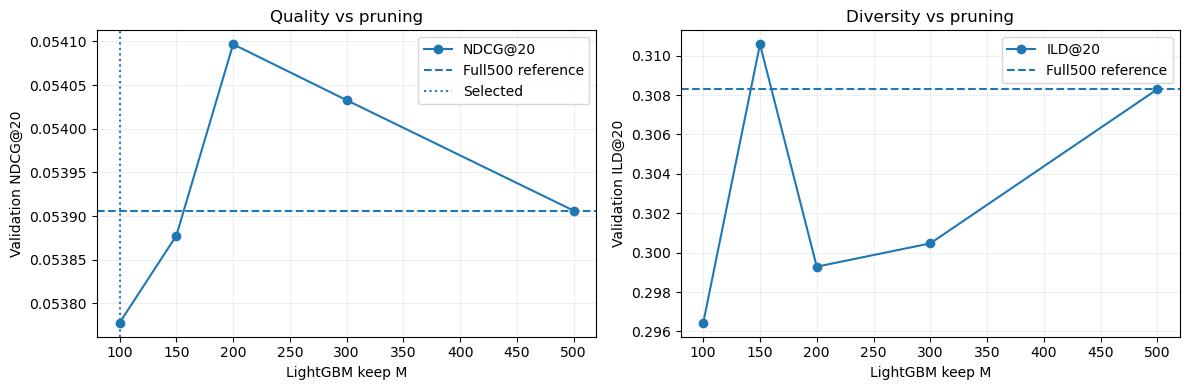

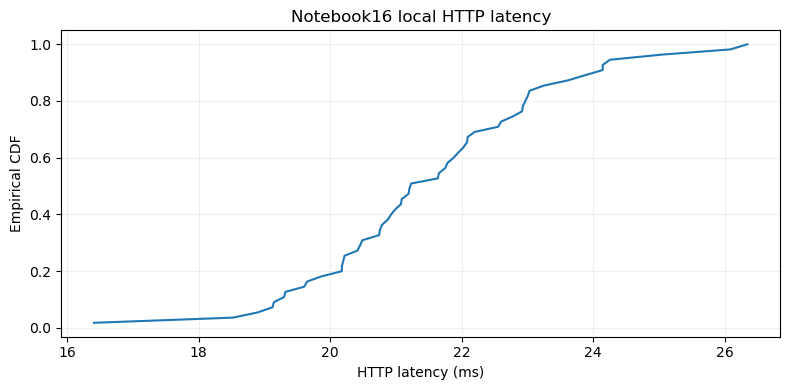

Saved C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\data\reports\notebook16_cascade_report.json


In [9]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
v20=VAL_METRICS[VAL_METRICS.k==20].sort_values('keep')
axes[0].plot(v20.keep,v20.ndcg,marker='o',label='NDCG@20');axes[0].axhline(b.ndcg,ls='--',label='Full500 reference')
axes[0].axvline(SELECTED_KEEP,ls=':',label='Selected');axes[0].set(xlabel='LightGBM keep M',ylabel='Validation NDCG@20',title='Quality vs pruning');axes[0].legend();axes[0].grid(alpha=.2)
axes[1].plot(v20.keep,v20.intra_list_diversity,marker='o',label='ILD@20');axes[1].axhline(b.intra_list_diversity,ls='--',label='Full500 reference');axes[1].set(xlabel='LightGBM keep M',ylabel='Validation ILD@20',title='Diversity vs pruning');axes[1].legend();axes[1].grid(alpha=.2)
fig.tight_layout();fig.savefig(PLOTS/'notebook16_validation_tradeoff.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(8,4));v=np.sort(SAMPLES.http_ms.to_numpy());ax.plot(v,np.arange(1,len(v)+1)/len(v));ax.set(xlabel='HTTP latency (ms)',ylabel='Empirical CDF',title='Notebook16 local HTTP latency');ax.grid(alpha=.2);fig.tight_layout();fig.savefig(PLOTS/'notebook16_http_latency_cdf.png',dpi=160);plt.show()
report={'notebook':'16_true_multistage_cascade','seed':SEED,'environment':{'python':sys.version.split()[0],'platform':platform.platform()},
        'architecture':{'retrieval':'cached Notebook08 Top500','features':'cached Notebook09','lightgbm':'real model inference Top500',
                        'deepfm':'real inference only selected TopM','mmr_lambda':LAM,'mmr_pool':150,'mmr_depth':100},
        'validation_selection':CONFIG,'validation_metrics':VAL_METRICS.to_dict('records'),
        'test_metrics':TEST_METRICS.to_dict('records'),
        'test_overlap':{'mean_top20_overlap_fraction':float(OVERLAP.top20_overlap_count.mean()/20),
                        'top20_exact_rate':float(OVERLAP.top20_exact.mean()),'mean_jaccard':float(OVERLAP.top20_jaccard.mean())},
        'serving_audit':{'sampled_users':len(PARITY),'top20_score_replay_exact_rate':float(PARITY.exact_match.mean()),
                         'fine_rank_count':SELECTED_KEEP},
        'benchmark':{'warmup':WARMUP,'timed_requests':len(SAMPLES),'sequential':True,'http':HTTP,'server':SERVER,
                     'stage_latency':STAGE_METRICS.to_dict('records')},
        'limitations':['Precomputed retrieval/features; no live event processing','Validation uses cached frozen model scores; serving uses real inference',
                       'Only one selected Test configuration evaluated','No concurrency/cold-start/load testing','Test reference parity is not expected after pruning',
                       'Small sequential local benchmark; no production latency claim']}
(REP/'notebook16_cascade_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf-8')
print('Saved',REP/'notebook16_cascade_report.json')

In [10]:
client.close()
if server is not None and server.poll() is None:
    server.terminate()
    try:server.wait(timeout=15)
    except subprocess.TimeoutExpired:server.kill()
con.close()
print('Notebook16 complete. Upload data/reports/notebook16_cascade_report.json for analysis.')

Notebook16 complete. Upload data/reports/notebook16_cascade_report.json for analysis.


## Completion checklist

- Validation-only pruning selection with fixed guardrails
- Test metrics: Recall/NDCG/HitRate/Category Coverage/ILD at 20/50/100
- Top-20 overlap versus Notebook13 full-500 reference
- FastAPI actual LightGBM Top-500 + DeepFM Top-M inference, frozen MMR λ=0.9
- Service-to-score-replay exact Top-20 audit
- Sequential local HTTP P50/P95/P99/QPS, stage latency, plots, CSV and JSON

**Important:** If `selected_keep=500`, the Validation guardrails did not permit pruning; this is a valid experimental outcome. DeepFM Top-M reduction must not be claimed in that case.